# Studio Proyek 3 — Fine-Tuning Transformer Pretrained untuk Klasifikasi Sentimen SmSA

**Mata Kuliah:** Pembelajaran Mendalam (IF25-40401) · Institut Teknologi Sumatera
**Kelompok:** 14

| Nama | NIM |
|---|---|
| Ahmad Ali Mukti | 123140155 |
| Anisah Octa Rohila |123140137 |

**Tugas:** klasifikasi sentimen kalimat Bahasa Indonesia (negatif / netral / positif) pada dataset **SmSA** (IndoNLU, Wilie dkk., 2020)
dengan membandingkan **3 backbone** × **3 strategi fine-tuning** × **3 seed** = **27 run**.

**Cara menjalankan (Google Colab):**
1. `Runtime → Change runtime type → T4 GPU`.
2. Jalankan dulu dengan `MODE = "cepat"` (uji fungsi singkat) untuk memastikan semua sel jalan.
3. Ubah ke `MODE = "penuh"` lalu `Runtime → Run all`. Hasil tiap run langsung di-*append* ke CSV, sehingga kalau sesi Colab terputus cukup jalankan ulang — run yang sudah selesai otomatis dilewati.

## 1. Rancangan Eksperimen (Soal 1) — ditulis SEBELUM eksperimen pertama

### 1.1 Dataset dan alasan pemilihan
- **Dataset:** SmSA (*Sentence-level Sentiment Analysis*) dari benchmark IndoNLU, berisi ulasan/kalimat Bahasa Indonesia berlabel manusia: `negative`, `neutral`, `positive`.
- **Pembagian resmi:** 6.000 data latih berstrata (seed subset 42), seluruh validasi bersih (minimal 500), dan seluruh 500 contoh uji resmi berlabel.
- **Validasi:** hanya untuk memilih checkpoint dengan F1 makro tertinggi dari tiga epoch. Jika seri, pilih yang lebih awal.
- **Uji:** setelah checkpoint terbaik dimuat, lakukan satu putaran prediksi tiap run pada seluruh 500 contoh di [test_preprocess.tsv](https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/test_preprocess.tsv).
- **Pembersihan:** rapikan spasi untuk pencocokan, singkirkan teks kosong, duplikat dan teks berlabel konflik dari latih dan validasi. Buang kemunculan teks uji dari latih/validasi serta teks latih dari validasi. Pertahankan semua baris dan urutan uji.
- **Alasan:** SmSA disarankan pada slide 10 dan relevan untuk sentimen bahasa Indonesia. Batas latih resmi 3.000–6.000. Pilihan 6.000 mempertahankan lebih banyak contoh kelas minoritas sambil membatasi biaya 27 run.

### 1.2 Matriks eksperimen (backbone × strategi), tiap sel dijalankan 3 seed

| Backbone \ Strategi | Full Fine-Tuning | Partial Freezing | Linear Probing |
|---|---|---|---|
| `bert-base-multilingual-cased` (mBERT, baseline) | ✔ 3 seed | ✔ 3 seed | ✔ 3 seed |
| `distilbert-base-multilingual-cased` (DistilmBERT) | ✔ 3 seed | ✔ 3 seed | ✔ 3 seed |
| `indobenchmark/indobert-base-p1` (IndoBERT) | ✔ 3 seed | ✔ 3 seed | ✔ 3 seed |

Total = 3 × 3 × 3 = **27 run**. Semua run memakai **head replacement**, yaitu head baru berupa proyeksi linear pada token pertama, berukuran `num_labels = 3`.
Model khusus bahasa Inggris (bert-base-uncased, dll.) **tidak dipakai** karena faktor bahasanya membuat perbandingan tidak adil.

### 1.3 Variabel terkendali (dikunci untuk semua run)

| Variabel | Nilai |
|---|---|
| `max_length` | 128 token (truncation, *dynamic padding*) |
| Batch size | 32 (train), 64 (eval) |
| Jumlah epoch | 3, checkpoint terbaik dipilih lewat F1 makro validasi |
| Seed | **42, 123, 2024** (sama untuk semua kombinasi), `set_seed()` dipanggil di awal tiap run |
| Optimizer / scheduler | AdamW, linear decay, warmup 10 %, weight decay 0,01 |
| Presisi | fp16 (mixed precision) di GPU |
| Learning rate | Full FT & Partial: **2e-5** · Linear Probing: **1e-3** (head acak yang dilatih sendirian butuh lr jauh lebih besar) |
| Subset latih / evaluasi | 6.000 (stratified, seed 42) / validasi bersih ≥ 500 / uji resmi 500 |
| Metrik | akurasi, F1 makro, waktu latih, waktu inferensi (ms/kalimat), parameter total & dilatih, memori puncak GPU |

### 1.4 Definisi strategi
- **Full fine-tuning:** semua parameter dilatih. Ini menjadi *baseline* strategi.
- **Partial freezing:** embedding + **separuh lapis encoder awal** dibekukan (12 lapis → 6 awal beku; DistilBERT 6 lapis → 3 awal beku).
- **Linear probing:** seluruh encoder dibekukan dan dalam mode evaluasi. Hanya head linear baru pada token pertama yang dilatih.
- Pemeriksaan otomatis: jumlah parameter yang dilatih harus berurutan **probing < partial < full**.

### 1.5 Hipotesis
- **H1 (backbone):** IndoBERT menghasilkan F1 makro tertinggi, diikuti mBERT lalu DistilmBERT, karena IndoBERT di-*pretrain* pada korpus Indonesia (Indo4B), sehingga kosakata dan representasinya lebih cocok untuk SmSA.
- **H2 (strategi):** Full FT > Partial Freezing > Linear Probing pada F1 makro. Partial freezing diperkirakan hanya sedikit di bawah full FT (selisih < 2 poin F1) dengan parameter dilatih jauh lebih sedikit, sedangkan linear probing turun jauh karena representasi [CLS] yang beku tidak disesuaikan dengan tugas.
- **H3 (efisiensi):** DistilmBERT kira-kira **2× lebih cepat** saat inferensi dan latih dibanding mBERT (6 vs 12 lapis) dengan penurunan F1 paling banyak 2 poin, sehingga menjadi kandidat untuk kebutuhan *real-time* dengan anggaran komputasi terbatas.

In [ ]:
# ===== RANCANGAN (wajib terisi sebelum MODE="penuh" boleh berjalan) =====
RANCANGAN = {
    "dataset": "SmSA (IndoNLU) - train/valid/test resmi. Validasi bersih ≥500 memilih checkpoint F1 makro terbaik; uji resmi berlabel (500) sekali per run",
    "alasan_dataset_subset": "Sentimen Indonesia yang relevan dunia nyata; subset latih 6000 stratified agar distribusi kelas terjaga dalam batas 3.000–6.000 pada slide",
    "matriks": "3 backbone (mBERT, DistilmBERT, IndoBERT) x 3 strategi (full, partial, probing) x 3 seed = 27 run",
    "H1": "IndoBERT > mBERT > DistilmBERT pada F1 makro karena pretraining berbahasa Indonesia",
    "H2": "Full FT > Partial > Linear Probing; partial < 2 poin F1 di bawah full dengan parameter dilatih jauh lebih sedikit",
    "H3": "DistilmBERT ~2x lebih cepat (latih & inferensi) dari mBERT dengan penurunan F1 kecil",
    "alasan_desain": "Satu protokol identik untuk semua backbone; lr disesuaikan per strategi; 3 seed untuk melaporkan mean +- std",
    "variabel_terkendali": "max_length=128, batch=32, epoch=3, seed={42,123,2024}, AdamW, warmup 10%, wd 0.01, fp16, lr full/partial=2e-5, probing=1e-3",
}

## 2. Setup & Konfigurasi

In [ ]:
!pip -q install "transformers==4.57.1" "accelerate>=1.1,<2" scikit-learn sentencepiece seaborn

In [ ]:
import os, gc, json, time, hashlib
from tempfile import TemporaryDirectory
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import transformers
from transformers import (AutoTokenizer, AutoConfig, AutoModel, DataCollatorWithPadding,
                          Trainer, TrainingArguments, set_seed)

from transformers.modeling_outputs import SequenceClassifierOutput
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"
print("transformers", transformers.__version__, "| torch", torch.__version__, "| device:", GPU_NAME)
assert DEVICE == "cuda", "Aktifkan GPU: Runtime -> Change runtime type -> T4 GPU"

transformers 4.57.1 | torch 2.14.1+cu130 | device: Tesla T4


In [ ]:
# ===================== KONFIGURASI UTAMA =====================
MODE = "penuh"          # "cepat" = smoke test (1 seed, data kecil, 1 epoch) | "penuh" = eksperimen resmi 27 run

BACKBONES = {
    "mBERT":       "bert-base-multilingual-cased",
    "DistilmBERT": "distilbert-base-multilingual-cased",
    "IndoBERT":    "indobenchmark/indobert-base-p1",
}
EXTRA_BACKBONES = {     # opsional (nilai plus) - aktifkan dengan memindahkan ke BACKBONES
    # "XLM-R": "xlm-roberta-base",
}
STRATEGIES = ["full", "partial", "probing"]
LR = {"full": 2e-5, "partial": 2e-5, "probing": 1e-3}

if MODE not in {"cepat", "penuh"}:
    raise ValueError("MODE harus cepat atau penuh.")

if MODE == "penuh":
    SEEDS, EPOCHS, TRAIN_SUBSET, VALID_SUBSET = [42, 123, 2024], 3, 6000, None
else:
    SEEDS, EPOCHS, TRAIN_SUBSET, VALID_SUBSET = [42], 1, 500, 300

MAX_LENGTH, TRAIN_BS, EVAL_BS = 128, 32, 64
WARMUP_RATIO, WEIGHT_DECAY = 0.1, 0.01
N_LATENCY = 200          # jumlah kalimat untuk mengukur waktu inferensi (batch = 1)
DATASET = "smsa"
SUBSET_SEED, TEST_SIZE = 42, 500

CONFIG = dict(mode=MODE, dataset=DATASET, backbones=BACKBONES, strategies=STRATEGIES, lr=LR, seeds=SEEDS,
              epochs=EPOCHS, train_subset=TRAIN_SUBSET, valid_subset=VALID_SUBSET, max_length=MAX_LENGTH,
              train_bs=TRAIN_BS, eval_bs=EVAL_BS, warmup=WARMUP_RATIO, wd=WEIGHT_DECAY,
              subset_seed=SUBSET_SEED, test_size=TEST_SIZE, n_latency=N_LATENCY,
              protocol="valid-best-f1-official-test-cls-linear-v1",
              transformers=transformers.__version__)

# Pembagian kerja antar anggota (opsional): isi subset nama backbone, mis. ["mBERT"] di akun A dan
# ["DistilmBERT", "IndoBERT"] di akun B. Tidak memengaruhi KODE, jadi CSV bisa digabung.
RUN_BACKBONES = list(BACKBONES)

# ===== Guard rancangan =====
if MODE == "penuh":
    kosong = [k for k, v in RANCANGAN.items() if not str(v).strip() or "TODO" in str(v)]
    if kosong:
        raise ValueError(f"Sel RANCANGAN belum lengkap: {kosong}. Isi dulu sebelum menjalankan mode penuh.")

print(f"MODE={MODE} | seeds={SEEDS} | epochs={EPOCHS} | subset latih={TRAIN_SUBSET}")
print(f"Total run direncanakan: {len(RUN_BACKBONES) * len(STRATEGIES) * len(SEEDS)}")

MODE=penuh | seeds=[42, 123, 2024] | epochs=3 | subset latih=6000
Total run direncanakan: 27


In [ ]:
# Simpan hasil ke Google Drive agar tidak hilang saat sesi Colab terputus
SIMPAN_KE_DRIVE = True
try:
    if SIMPAN_KE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = "/content/drive/MyDrive/Studio3_SmSA"
    else:
        OUT_DIR = "hasil"
except Exception as e:
    print("Drive tidak tersedia, simpan lokal:", e)
    OUT_DIR = "hasil"
os.makedirs(OUT_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Data SmSA: unduh, bersihkan, subset

In [ ]:
BASE_URL = "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/"
LABEL2ID = {"negative": 0, "neutral": 1, "positive": 2}
LABEL_IDS = list(LABEL2ID.values())

def load_tsv(name):
    df = pd.read_csv(BASE_URL + name, sep="\t", header=None, names=["text", "label"],
                     quoting=3, dtype=str, keep_default_na=False)
    df["label"] = df["label"].str.strip()
    if not df["label"].isin(LABEL2ID).all():
        raise ValueError(f"Label pada {name} harus negative, neutral, atau positive.")
    df["y"] = df["label"].map(LABEL2ID)
    return df

def text_key(text):
    return " ".join(text.split())

def clean(df, name, excluded_keys):
    data = df.assign(key=df["text"].map(text_key))
    data = data[data["key"].ne("")].drop_duplicates(subset=["key", "label"])
    label_counts = data.groupby("key")["label"].nunique()
    data = data[~data["key"].isin(label_counts[label_counts > 1].index)]
    overlap = data["key"].isin(excluded_keys)
    print(f"{name}: awal={len(df)}, setelah pembersihan internal={len(data)}, "
          f"overlap antarsplit dibuang={int(overlap.sum())}")
    return data.loc[~overlap].copy()

def stratified_subset(df, size):
    if size is None or size == len(df):
        return df.reset_index(drop=True)
    if not 0 < size < len(df):
        raise ValueError(f"Subset {size} tidak tersedia dari {len(df)} sampel bersih.")
    selected, _ = train_test_split(df, train_size=size, stratify=df["y"], random_state=SUBSET_SEED)
    return selected.reset_index(drop=True)

train_raw = load_tsv("train_preprocess.tsv")
valid_raw = load_tsv("valid_preprocess.tsv")
test_df = load_tsv("test_preprocess.tsv")
test_keys = set(test_df["text"].map(text_key))
assert len(test_df) == TEST_SIZE and "" not in test_keys, "Gunakan 500 baris uji resmi berlabel."
train_clean = clean(train_raw, "Latih", test_keys)
valid_clean = clean(valid_raw, "Validasi", test_keys | set(train_clean["key"]))
train_df = stratified_subset(train_clean, TRAIN_SUBSET)
valid_df = stratified_subset(valid_clean, VALID_SUBSET)

if MODE == "penuh":
    assert 3000 <= len(train_df) <= 6000, "Data latih harus 3.000–6.000."
    assert len(valid_df) >= 500, "Validasi harus minimal 500 data."

splits = {"latih": train_df, "validasi": valid_df, "uji": test_df}
for name, split in splits.items():
    assert set(split["y"]) == set(LABEL_IDS), f"Ketiga label harus tersedia di split {name}."
assert set(train_df["key"]).isdisjoint(valid_df["key"])
assert test_keys.isdisjoint(train_df["key"]) and test_keys.isdisjoint(valid_df["key"])

def split_fingerprint(df):
    rows = df[["text", "label"]].to_csv(index=False, lineterminator="\n")
    return hashlib.sha256(rows.encode("utf-8")).hexdigest()

CONFIG["split_fingerprints"] = {name: split_fingerprint(df) for name, df in splits.items()}
KODE = hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest()[:8]
print(f"Latih={len(train_df)} | Validasi={len(valid_df)} | Uji={len(test_df)} | Kode={KODE}")
HASIL_CSV = os.path.join(OUT_DIR, f"hasil_{DATASET}_{KODE}.csv")
REKAP_CSV = os.path.join(OUT_DIR, f"rekap_agregat_{DATASET}_{KODE}.csv")
print("Hasil per run :", HASIL_CSV)
print("Rekap agregat :", REKAP_CSV)
TFIDF_CSV = os.path.join(OUT_DIR, f"baseline_tfidf_{DATASET}_{KODE}.csv")

Latih: awal=11000, setelah pembersihan internal=10933, overlap antarsplit dibuang=0
Validasi: awal=1260, setelah pembersihan internal=1260, overlap antarsplit dibuang=14
Latih=6000 | Validasi=1246 | Uji=500 | Kode=22583772
Hasil per run : /content/drive/MyDrive/Studio3_SmSA/hasil_smsa_22583772.csv
Rekap agregat : /content/drive/MyDrive/Studio3_SmSA/rekap_agregat_smsa_22583772.csv


label,negative,neutral,positive,total
Latih resmi,3436,1148,6416,11000
Validasi resmi,394,131,735,1260
latih,1872,625,3503,6000
validasi,389,129,728,1246
uji,204,88,208,500


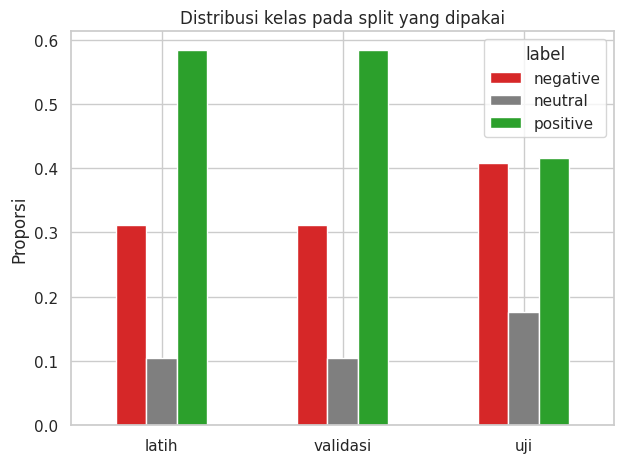

In [ ]:
counts = pd.DataFrame({
    name: df["label"].value_counts().reindex(LABEL2ID, fill_value=0)
    for name, df in {"Latih resmi": train_raw, "Validasi resmi": valid_raw, **splits}.items()
}).T
counts["total"] = counts.sum(axis=1)
display(counts)
used = counts.loc[list(splits)]
ax = used[list(LABEL2ID)].div(used["total"], axis=0).plot.bar(
    color=["#d62728", "#7f7f7f", "#2ca02c"], rot=0
)
ax.set(title="Distribusi kelas pada split yang dipakai", ylabel="Proporsi")
plt.tight_layout()
plt.show()

## 4. Head replacement dan strategi fine-tuning
Semua model memakai head linear tiga kelas yang baru pada representasi token pertama dari encoder. Saat probing, encoder dijalankan dalam mode evaluasi agar dropout tidak mengubah representasi selama head dilatih.

In [ ]:
class SmSAClassifier(torch.nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.classifier = torch.nn.Linear(encoder.config.hidden_size, len(LABEL_IDS))
        self.encoder_frozen = False

    def train(self, mode=True):
        super().train(mode)
        if self.encoder_frozen:
            self.encoder.eval()
        return self

    def forward(self, input_ids, attention_mask=None, token_type_ids=None, labels=None):
        inputs = {"input_ids": input_ids, "attention_mask": attention_mask}
        if token_type_ids is not None:
            inputs["token_type_ids"] = token_type_ids
        cls = self.encoder(**inputs).last_hidden_state[:, 0]
        logits = self.classifier(cls)
        loss = torch.nn.functional.cross_entropy(logits, labels) if labels is not None else None
        return SequenceClassifierOutput(loss=loss, logits=logits)

def get_encoder_layers(model):
    if model.encoder.config.model_type == "distilbert":
        return model.encoder.transformer.layer
    return model.encoder.encoder.layer

def apply_strategy(model, strategy):
    if strategy not in STRATEGIES:
        raise ValueError(f"Strategi tidak dikenal: {strategy}")
    model.requires_grad_(True)
    model.encoder_frozen = strategy == "probing"
    if strategy == "partial":
        model.encoder.embeddings.requires_grad_(False)
        layers = get_encoder_layers(model)
        for layer in layers[:len(layers) // 2]:
            layer.requires_grad_(False)
    elif model.encoder_frozen:
        model.encoder.requires_grad_(False)
    return model.train()

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def load_model(ckpt):
    config = AutoConfig.from_pretrained(ckpt)
    options = {} if config.model_type == "distilbert" else {"add_pooling_layer": False}
    return SmSAClassifier(AutoModel.from_pretrained(ckpt, config=config, **options))

In [ ]:
# Pemeriksaan: parameter dilatih harus berurutan probing < partial < full untuk setiap backbone
param_rows = []
for name, ckpt in BACKBONES.items():
    m = load_model(ckpt)
    cnt = {}
    for s in STRATEGIES:
        apply_strategy(m, s)
        total, trainable = count_params(m)
        cnt[s] = trainable
        param_rows.append(dict(backbone=name, strategi=s, n_layer=len(get_encoder_layers(m)), params_total=total,
                               params_trainable=trainable, pct_trainable=100 * trainable / total))
    assert cnt["probing"] < cnt["partial"] < cnt["full"], f"Urutan parameter salah untuk {name}: {cnt}"
    assert not m.encoder.training and m.classifier.training
    print(f"{name}: head linear = {cnt['probing']:,} parameter")
    del m; gc.collect()

param_df = pd.DataFrame(param_rows)
display(param_df.style.format({"params_total": "{:,}", "params_trainable": "{:,}", "pct_trainable": "{:.3f}%"}))
print("OK: probing < partial < full untuk semua backbone")

mBERT: head linear = 2,307 parameter
DistilmBERT: head linear = 2,307 parameter


Some weights of the model checkpoint at indobenchmark/indobert-base-p1 were not used when initializing BertModel: ['pooler.dense.bias', 'pooler.dense.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


IndoBERT: head linear = 2,307 parameter


,backbone,strategi,n_layer,params_total,params_trainable,pct_trainable
0,mBERT,full,12,"177,265,155","177,265,155",100.000%
1,mBERT,partial,12,"177,265,155","42,529,539",23.992%
2,mBERT,probing,12,"177,265,155","2,307",0.001%
3,DistilmBERT,full,6,"134,736,387","134,736,387",100.000%
4,DistilmBERT,partial,6,"134,736,387","21,265,923",15.783%
5,DistilmBERT,probing,6,"134,736,387","2,307",0.002%
6,IndoBERT,full,12,"123,853,059","123,853,059",100.000%
7,IndoBERT,partial,12,"123,853,059","42,529,539",34.339%
8,IndoBERT,probing,12,"123,853,059","2,307",0.002%


OK: probing < partial < full untuk semua backbone


## 5. Fungsi satu run eksperimen
Validasi pada akhir tiap epoch memilih checkpoint berdasarkan F1 makro. Setelah checkpoint terbaik dimuat, satu putaran prediksi pada uji resmi menghasilkan akurasi, F1 makro dan matriks kebingungan. Latensi diukur terpisah memakai teks dari latih.

In [ ]:
class TextDataset(torch.utils.data.Dataset):
    def __init__(self, enc, labels):
        self.enc, self.labels = enc, labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.labels[i])
        return item

_tok_cache = {}
def get_tokenized(backbone):
    if backbone not in _tok_cache:
        tok = AutoTokenizer.from_pretrained(BACKBONES[backbone])
        def encode(df):
            enc = tok(df["text"].tolist(), truncation=True, max_length=MAX_LENGTH)
            return TextDataset(enc, df["y"].to_numpy())

        _tok_cache[backbone] = (tok, encode(train_df), encode(valid_df), encode(test_df))
    return _tok_cache[backbone]

LATENCY_TEXTS = train_df["text"].sample(n=N_LATENCY, random_state=SUBSET_SEED).tolist()

@torch.inference_mode()
def measure_latency_ms(model, tok, texts=LATENCY_TEXTS, warmup=10):
    model.eval()
    def one(t):
        x = tok(t, truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(DEVICE)
        model(**x)
    for t in texts[:warmup]:
        one(t)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for t in texts:
        one(t)
    torch.cuda.synchronize()
    return 1000 * (time.perf_counter() - t0) / len(texts)

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=LABEL_IDS, average="macro", zero_division=0)

def validation_metrics(pred):
    return {"f1_macro": macro_f1(pred.label_ids, pred.predictions.argmax(-1))}

def run_experiment(backbone, strategy, seed):
    set_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    tok, train_ds, valid_ds, test_ds = get_tokenized(backbone)
    model = apply_strategy(load_model(BACKBONES[backbone]), strategy)
    total, trainable = count_params(model)
    total_steps = int(np.ceil(len(train_ds) / TRAIN_BS)) * EPOCHS

    with TemporaryDirectory(prefix="studio3-checkpoints-") as checkpoint_dir:
        args = TrainingArguments(
            output_dir=checkpoint_dir, num_train_epochs=EPOCHS, learning_rate=LR[strategy],
            per_device_train_batch_size=TRAIN_BS, per_device_eval_batch_size=EVAL_BS,
            warmup_steps=int(WARMUP_RATIO * total_steps), weight_decay=WEIGHT_DECAY,
            lr_scheduler_type="linear", optim="adamw_torch",
            eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
            save_only_model=True,
            load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
            fp16=True, seed=seed, data_seed=seed, logging_strategy="no",
            report_to="none", dataloader_num_workers=0, disable_tqdm=True,
        )
        trainer = Trainer(
            model=model, args=args, train_dataset=train_ds, eval_dataset=valid_ds,
            data_collator=DataCollatorWithPadding(tok), compute_metrics=validation_metrics,
        )
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
        start = time.perf_counter()
        trainer.train()
        torch.cuda.synchronize()
        train_time = time.perf_counter() - start
        peak_mem = torch.cuda.max_memory_allocated() / 1024**2

        validation = [entry for entry in trainer.state.log_history if "eval_f1_macro" in entry]
        assert len(validation) == EPOCHS, "Validasi harus dilakukan di setiap akhir epoch."
        best = max(validation, key=lambda entry: entry["eval_f1_macro"])
        assert trainer.state.best_model_checkpoint and best["eval_f1_macro"] == trainer.state.best_metric
        trainer.compute_metrics = None
        pred = trainer.predict(test_ds, metric_key_prefix="test")
        y_true, y_pred = pred.label_ids, pred.predictions.argmax(-1)
        assert len(y_true) == TEST_SIZE
        latency = measure_latency_ms(model, tok)
        row = dict(
            kode=KODE, dataset=DATASET, backbone=backbone, checkpoint=BACKBONES[backbone],
            model_revision=getattr(model.encoder.config, "_commit_hash", None),
            strategi=strategy, seed=seed, lr=LR[strategy], epochs=EPOCHS,
            best_epoch=round(best["epoch"]), best_valid_f1_macro=best["eval_f1_macro"],
            n_train=len(train_ds), n_valid=len(valid_ds), n_test=len(test_ds),
            accuracy=accuracy_score(y_true, y_pred), f1_macro=macro_f1(y_true, y_pred),
            train_time_s=train_time, infer_ms_per_sentence=latency,
            params_total=total, params_trainable=trainable, pct_trainable=100 * trainable / total,
            peak_mem_mb=peak_mem, gpu=GPU_NAME, timestamp=datetime.now().isoformat(timespec="seconds"),
            cm=json.dumps(confusion_matrix(y_true, y_pred, labels=LABEL_IDS).tolist()),
        )
        del trainer, model
    gc.collect()
    torch.cuda.empty_cache()
    return row

## 6. Menjalankan matriks eksperimen (Soal 2 & 3)
Kode hasil mencakup konfigurasi dan sidik jari split. Setiap run langsung disimpan ke `hasil_smsa_<kode>.csv`. Run yang sudah ada di CSV **dilewati**, sehingga sel ini aman dijalankan ulang setelah sesi terputus.

In [ ]:
RUN_KEY = ["backbone", "strategi", "seed"]
EXPECTED_RUNS = {(b, s, seed) for b in BACKBONES for s in STRATEGIES for seed in SEEDS}

def read_run_results(path):
    rows = pd.read_csv(path, dtype={"kode": str})
    if not (rows["kode"].eq(KODE).all() and rows["n_test"].eq(TEST_SIZE).all()):
        raise ValueError(f"Konfigurasi atau ukuran uji di {path} tidak cocok.")
    keys = set(rows[RUN_KEY].itertuples(index=False, name=None))
    if len(keys) != len(rows) or not keys <= EXPECTED_RUNS:
        raise ValueError(f"Kombinasi run duplikat atau tidak dikenal di {path}.")
    return rows

def save_run_results(rows):
    rows.to_csv(HASIL_CSV + ".tmp", index=False)
    os.replace(HASIL_CSV + ".tmp", HASIL_CSV)

previous = read_run_results(HASIL_CSV) if os.path.exists(HASIL_CSV) else pd.DataFrame()
done = set(previous[RUN_KEY].itertuples(index=False, name=None)) if not previous.empty else set()
jobs = [(b, s, seed) for b in RUN_BACKBONES for s in STRATEGIES for seed in SEEDS
        if (b, s, seed) not in done]
print(f"Run tersimpan: {len(done)} | Run tersisa untuk backbone terpilih: {len(jobs)}")

t_all = time.perf_counter()
for i, (b, s, seed) in enumerate(jobs, 1):
    row = run_experiment(b, s, seed)
    previous = pd.concat([previous, pd.DataFrame([row])], ignore_index=True)
    save_run_results(previous)
    print(f"[{i:2d}/{len(jobs)}] {b} / {s} / seed={seed} | epoch terbaik={row['best_epoch']} "
          f"| akurasi uji={row['accuracy']:.4f} | F1 uji={row['f1_macro']:.4f} "
          f"| latih={row['train_time_s']:.0f}s | inferensi={row['infer_ms_per_sentence']:.2f} ms")
print(f"Durasi sesi: {(time.perf_counter() - t_all) / 60:.1f} menit")

Run tersimpan: 0 | Run tersisa untuk backbone terpilih: 27
{'eval_loss': 0.35366204380989075, 'eval_f1_macro': 0.8181053994935734, 'eval_runtime': 2.3933, 'eval_samples_per_second': 520.612, 'eval_steps_per_second': 8.357, 'epoch': 1.0}
{'eval_loss': 0.36198511719703674, 'eval_f1_macro': 0.8289328944989321, 'eval_runtime': 2.2193, 'eval_samples_per_second': 561.446, 'eval_steps_per_second': 9.012, 'epoch': 2.0}
{'eval_loss': 0.31268447637557983, 'eval_f1_macro': 0.8671993192332303, 'eval_runtime': 2.2392, 'eval_samples_per_second': 556.46, 'eval_steps_per_second': 8.932, 'epoch': 3.0}
{'train_runtime': 166.3218, 'train_samples_per_second': 108.224, 'train_steps_per_second': 3.391, 'train_loss': 0.35543574339954565, 'epoch': 3.0}
[ 1/27] mBERT / full / seed=42 | epoch terbaik=3 | akurasi uji=0.8220 | F1 uji=0.7801 | latih=167s | inferensi=10.99 ms
{'eval_loss': 0.3603404462337494, 'eval_f1_macro': 0.8265154337052772, 'eval_runtime': 2.0959, 'eval_samples_per_second': 594.49, 'eval_steps

Some weights of the model checkpoint at indobenchmark/indobert-base-p1 were not used when initializing BertModel: ['pooler.dense.bias', 'pooler.dense.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


{'eval_loss': 0.1799229234457016, 'eval_f1_macro': 0.8980464865522336, 'eval_runtime': 1.6436, 'eval_samples_per_second': 758.091, 'eval_steps_per_second': 12.168, 'epoch': 1.0}
{'eval_loss': 0.2409278005361557, 'eval_f1_macro': 0.8976650781068348, 'eval_runtime': 1.7497, 'eval_samples_per_second': 712.107, 'eval_steps_per_second': 11.43, 'epoch': 2.0}
{'eval_loss': 0.23730245232582092, 'eval_f1_macro': 0.9106330674712105, 'eval_runtime': 1.6148, 'eval_samples_per_second': 771.633, 'eval_steps_per_second': 12.386, 'epoch': 3.0}
{'train_runtime': 125.8932, 'train_samples_per_second': 142.978, 'train_steps_per_second': 4.48, 'train_loss': 0.16827454803683234, 'epoch': 3.0}
[19/27] IndoBERT / full / seed=42 | epoch terbaik=3 | akurasi uji=0.9160 | F1 uji=0.8907 | latih=126s | inferensi=10.47 ms


Some weights of the model checkpoint at indobenchmark/indobert-base-p1 were not used when initializing BertModel: ['pooler.dense.bias', 'pooler.dense.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


{'eval_loss': 0.20112696290016174, 'eval_f1_macro': 0.9020670268814489, 'eval_runtime': 1.7664, 'eval_samples_per_second': 705.378, 'eval_steps_per_second': 11.322, 'epoch': 1.0}
{'eval_loss': 0.20135194063186646, 'eval_f1_macro': 0.9088147193949355, 'eval_runtime': 1.7701, 'eval_samples_per_second': 703.913, 'eval_steps_per_second': 11.299, 'epoch': 2.0}
{'eval_loss': 0.24684393405914307, 'eval_f1_macro': 0.9140197207809777, 'eval_runtime': 1.7245, 'eval_samples_per_second': 722.508, 'eval_steps_per_second': 11.597, 'epoch': 3.0}
{'train_runtime': 138.7344, 'train_samples_per_second': 129.744, 'train_steps_per_second': 4.065, 'train_loss': 0.17078042537608046, 'epoch': 3.0}
[20/27] IndoBERT / full / seed=123 | epoch terbaik=3 | akurasi uji=0.9180 | F1 uji=0.8941 | latih=139s | inferensi=10.46 ms


Some weights of the model checkpoint at indobenchmark/indobert-base-p1 were not used when initializing BertModel: ['pooler.dense.bias', 'pooler.dense.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


... (9 outputs left out)

Some weights of the model checkpoint at indobenchmark/indobert-base-p1 were not used when initializing BertModel: ['pooler.dense.bias', 'pooler.dense.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


{'eval_loss': 0.30233123898506165, 'eval_f1_macro': 0.865982669979021, 'eval_runtime': 1.6287, 'eval_samples_per_second': 765.018, 'eval_steps_per_second': 12.28, 'epoch': 1.0}
{'eval_loss': 0.2827718257904053, 'eval_f1_macro': 0.8689580044907851, 'eval_runtime': 1.7332, 'eval_samples_per_second': 718.898, 'eval_steps_per_second': 11.539, 'epoch': 2.0}
{'eval_loss': 0.2798483073711395, 'eval_f1_macro': 0.8708615879957549, 'eval_runtime': 1.6635, 'eval_samples_per_second': 749.044, 'eval_steps_per_second': 12.023, 'epoch': 3.0}
{'train_runtime': 74.7644, 'train_samples_per_second': 240.756, 'train_steps_per_second': 7.544, 'train_loss': 0.3233762971052887, 'epoch': 3.0}
[26/27] IndoBERT / probing / seed=123 | epoch terbaik=3 | akurasi uji=0.8380 | F1 uji=0.7924 | latih=75s | inferensi=9.87 ms


Some weights of the model checkpoint at indobenchmark/indobert-base-p1 were not used when initializing BertModel: ['pooler.dense.bias', 'pooler.dense.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


{'eval_loss': 0.29987478256225586, 'eval_f1_macro': 0.8524325586959164, 'eval_runtime': 1.6592, 'eval_samples_per_second': 750.983, 'eval_steps_per_second': 12.054, 'epoch': 1.0}
{'eval_loss': 0.29016292095184326, 'eval_f1_macro': 0.8594239729088523, 'eval_runtime': 1.7359, 'eval_samples_per_second': 717.771, 'eval_steps_per_second': 11.521, 'epoch': 2.0}
{'eval_loss': 0.279775470495224, 'eval_f1_macro': 0.8692287380794039, 'eval_runtime': 1.6043, 'eval_samples_per_second': 776.663, 'eval_steps_per_second': 12.466, 'epoch': 3.0}
{'train_runtime': 61.4914, 'train_samples_per_second': 292.724, 'train_steps_per_second': 9.172, 'train_loss': 0.32795279753123613, 'epoch': 3.0}
[27/27] IndoBERT / probing / seed=2024 | epoch terbaik=3 | akurasi uji=0.8500 | F1 uji=0.8041 | latih=62s | inferensi=10.08 ms
Durasi sesi: 46.0 menit


### (Opsional) Gabung hasil dari akun anggota lain
Jika run dibagi ke dua akun Colab (lewat `RUN_BACKBONES`), upload CSV milik anggota lain ke `OUT_DIR` dengan nama `hasil_smsa_<KODE>_part2.csv`, lalu jalankan sel ini.

In [ ]:
import glob

parts = sorted(glob.glob(os.path.join(OUT_DIR, f"hasil_{DATASET}_{KODE}*.csv")))
print("Berkas ditemukan:", [os.path.basename(path) for path in parts])
if len(parts) > 1:
    parts.sort(key=lambda path: path != HASIL_CSV)
    merged = pd.concat([read_run_results(path) for path in parts], ignore_index=True)
    save_run_results(merged.drop_duplicates(RUN_KEY, keep="first"))
    print(f"Total run gabungan: {len(read_run_results(HASIL_CSV))}")

Berkas ditemukan: ['hasil_smsa_22583772.csv']


## 7. Rekap agregat: rata-rata ± simpangan baku antar-seed

In [ ]:
hasil = read_run_results(HASIL_CSV)
completed = set(hasil[RUN_KEY].itertuples(index=False, name=None))
if completed != EXPECTED_RUNS:
    raise RuntimeError(f"Gabungkan seluruh hasil sebelum analisis. Run kurang: {sorted(EXPECTED_RUNS - completed)}")
metrics = ["accuracy", "f1_macro", "train_time_s", "infer_ms_per_sentence", "peak_mem_mb"]
order_b = [b for b in BACKBONES if b in hasil.backbone.unique()]
order_s = [s for s in STRATEGIES if s in hasil.strategi.unique()]

agg = hasil.groupby(["backbone", "strategi"]).agg(
    n_seed=("seed", "nunique"),
    **{f"{m}_mean": (m, "mean") for m in metrics},
    **{f"{m}_std": (m, "std") for m in metrics},
    params_total=("params_total", "first"), params_trainable=("params_trainable", "first"),
    pct_trainable=("pct_trainable", "first")).reset_index()
agg["backbone"] = pd.Categorical(agg["backbone"], order_b)
agg["strategi"] = pd.Categorical(agg["strategi"], order_s)
agg = agg.sort_values(["backbone", "strategi"]).reset_index(drop=True)
agg.insert(0, "kode", KODE)
agg.to_csv(REKAP_CSV, index=False)
print("Disimpan:", REKAP_CSV)

def pm(m, d=4, scale=1):
    def format_row(row):
        mean, std = row[m + "_mean"] * scale, row[m + "_std"] * scale
        return f"{mean:.{d}f} ± {std:.{d}f}" if pd.notna(std) else f"{mean:.{d}f}"
    return format_row

tabel = pd.DataFrame({
    "Backbone": agg.backbone, "Strategi": agg.strategi, "Seed": agg.n_seed,
    "Akurasi uji (%)": agg.apply(pm("accuracy", 2, 100), axis=1),
    "F1 makro uji (%)": agg.apply(pm("f1_macro", 2, 100), axis=1),
    "Waktu latih (s)": agg.apply(pm("train_time_s", 1), axis=1),
    "Inferensi (ms/kalimat)": agg.apply(pm("infer_ms_per_sentence", 2), axis=1),
    "Param total (M)": (agg.params_total / 1e6).round(1),
    "Param dilatih (M)": (agg.params_trainable / 1e6).round(3),
    "Memori puncak (MiB)": agg.apply(pm("peak_mem_mb", 0), axis=1),
})
display(tabel)

Disimpan: /content/drive/MyDrive/Studio3_SmSA/rekap_agregat_smsa_22583772.csv


,Backbone,Strategi,Seed,Akurasi uji (%),F1 makro uji (%),Waktu latih (s),Inferensi (ms/kalimat),Param total (M),Param dilatih (M),Memori puncak (MiB)
0,mBERT,full,3,82.27 ± 0.70,78.23 ± 0.69,158.0 ± 10.0,11.31 ± 0.91,177.3,177.265,3883 ± 11
1,mBERT,partial,3,73.93 ± 0.64,70.41 ± 0.78,99.9 ± 2.7,11.62 ± 1.81,177.3,42.530,1957 ± 4
2,mBERT,probing,3,60.47 ± 0.23,53.57 ± 0.31,72.4 ± 12.6,10.25 ± 0.16,177.3,0.002,878 ± 0
3,DistilmBERT,full,3,77.47 ± 0.12,73.41 ± 0.35,109.5 ± 0.7,6.17 ± 0.78,134.7,134.736,2618 ± 4
4,DistilmBERT,partial,3,67.60 ± 2.31,63.64 ± 2.53,82.2 ± 11.0,6.11 ± 0.96,134.7,21.266,1182 ± 2
5,DistilmBERT,probing,3,51.60 ± 0.72,42.84 ± 0.48,63.2 ± 11.2,5.28 ± 0.06,134.7,0.002,703 ± 0
6,IndoBERT,full,3,91.60 ± 0.20,88.95 ± 0.53,134.7 ± 7.1,11.29 ± 1.42,123.9,123.853,2998 ± 6
7,IndoBERT,partial,3,90.53 ± 1.15,86.99 ± 1.96,94.3 ± 7.8,11.16 ± 1.51,123.9,42.530,1615 ± 8
8,IndoBERT,probing,3,84.47 ± 0.61,79.61 ± 0.70,69.0 ± 6.6,10.06 ± 0.18,123.9,0.002,641 ± 0


### 7.1 Benchmark latensi inferensi dalam satu sesi
Untuk ketiga backbone, gunakan satu sesi GPU, FP32, batch 1, dan 200 teks yang sama dari subset latih. Waktu mencakup tokenisasi dan diukur setelah pemanasan serta sinkronisasi CUDA. Gunakan hasil ini pada perbandingan antar-backbone.

In [ ]:
lat_rows = []
for name, ckpt in BACKBONES.items():
    set_seed(0)
    tok = AutoTokenizer.from_pretrained(ckpt)
    m = load_model(ckpt).to(DEVICE)
    vals = [measure_latency_ms(m, tok) for _ in range(3)]
    lat_rows.append(dict(backbone=name, infer_ms_mean=np.mean(vals), infer_ms_std=np.std(vals, ddof=1),
                         params_total_M=sum(p.numel() for p in m.parameters()) / 1e6, gpu=GPU_NAME))
    del m; gc.collect(); torch.cuda.empty_cache()
lat_df = pd.DataFrame(lat_rows)
base = lat_df.set_index("backbone").loc["mBERT", "infer_ms_mean"]
lat_df["speedup_vs_mBERT"] = base / lat_df["infer_ms_mean"]
lat_df.to_csv(os.path.join(OUT_DIR, f"latensi_{DATASET}_{KODE}.csv"), index=False)
display(lat_df.round(3))

Some weights of the model checkpoint at indobenchmark/indobert-base-p1 were not used when initializing BertModel: ['pooler.dense.bias', 'pooler.dense.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


,backbone,infer_ms_mean,infer_ms_std,params_total_M,gpu,speedup_vs_mBERT
0,mBERT,8.592,1.463,177.265,Tesla T4,1.000
1,DistilmBERT,3.934,0.010,134.736,Tesla T4,2.184
2,IndoBERT,9.091,0.734,123.853,Tesla T4,0.945


## 8. Visualisasi

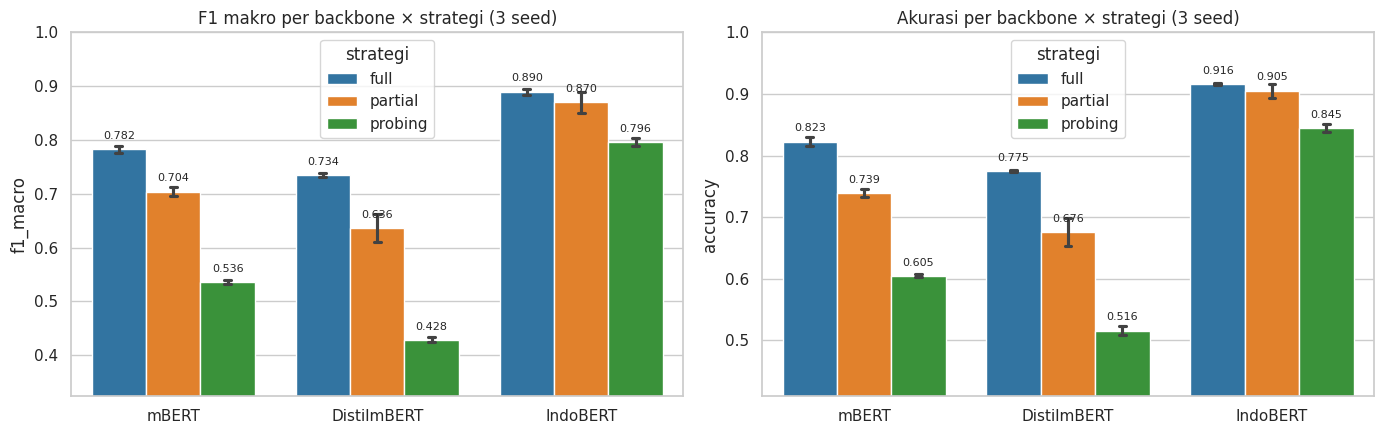

In [ ]:
sns.set_theme(style="whitegrid")
PAL = {"full": "#1f77b4", "partial": "#ff7f0e", "probing": "#2ca02c"}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (m, judul) in zip(axes, [("f1_macro", "F1 makro"), ("accuracy", "Akurasi")]):
    sns.barplot(data=hasil, x="backbone", y=m, hue="strategi", order=order_b, hue_order=order_s,
                palette=PAL, errorbar="sd", capsize=.1, ax=ax)
    ax.set_title(f"{judul} per backbone × strategi ({len(SEEDS)} seed)")
    ax.set_ylim(max(0, hasil[m].min() - 0.1), 1.0); ax.set_xlabel("")
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", fontsize=8, padding=6)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"fig_f1_akurasi_{KODE}.png"), dpi=150); plt.show()

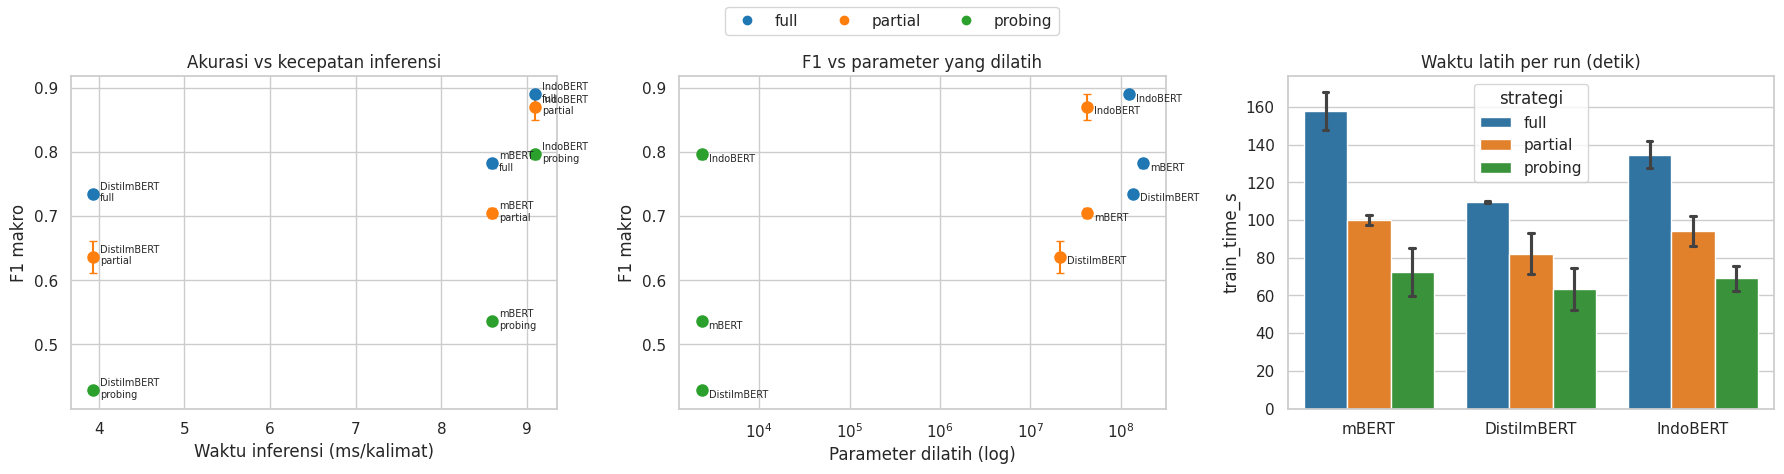

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# (a) F1 vs latensi dari sesi GPU yang sama
latency_by_backbone = lat_df.set_index("backbone")["infer_ms_mean"]
ax = axes[0]
for _, r in agg.iterrows():
    latency = latency_by_backbone[r.backbone]
    spread = r.f1_macro_std if pd.notna(r.f1_macro_std) else None
    ax.errorbar(latency, r.f1_macro_mean, yerr=spread, fmt="o", color=PAL[r.strategi], ms=8, capsize=3)
    ax.annotate(f"{r.backbone}\n{r.strategi}", (latency, r.f1_macro_mean), fontsize=7,
                xytext=(5, -5), textcoords="offset points")
ax.set_xlabel("Waktu inferensi (ms/kalimat)"); ax.set_ylabel("F1 makro"); ax.set_title("Akurasi vs kecepatan inferensi")

# (b) F1 vs parameter dilatih
ax = axes[1]
for _, r in agg.iterrows():
    spread = r.f1_macro_std if pd.notna(r.f1_macro_std) else None
    ax.errorbar(r.params_trainable, r.f1_macro_mean, yerr=spread, fmt="o", color=PAL[r.strategi], ms=8, capsize=3)
    ax.annotate(r.backbone, (r.params_trainable, r.f1_macro_mean), fontsize=7, xytext=(5, -5), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("Parameter dilatih (log)"); ax.set_ylabel("F1 makro"); ax.set_title("F1 vs parameter yang dilatih")

# (c) waktu latih
sns.barplot(data=hasil, x="backbone", y="train_time_s", hue="strategi", order=order_b, hue_order=order_s,
            palette=PAL, errorbar="sd", capsize=.1, ax=axes[2])
axes[2].set_title("Waktu latih per run (detik)"); axes[2].set_xlabel("")

from matplotlib.lines import Line2D
fig.legend([Line2D([], [], marker="o", ls="", color=c) for c in PAL.values()], PAL.keys(), loc="upper center", ncol=3)
plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.savefig(os.path.join(OUT_DIR, f"fig_tradeoff_{KODE}.png"), dpi=150); plt.show()

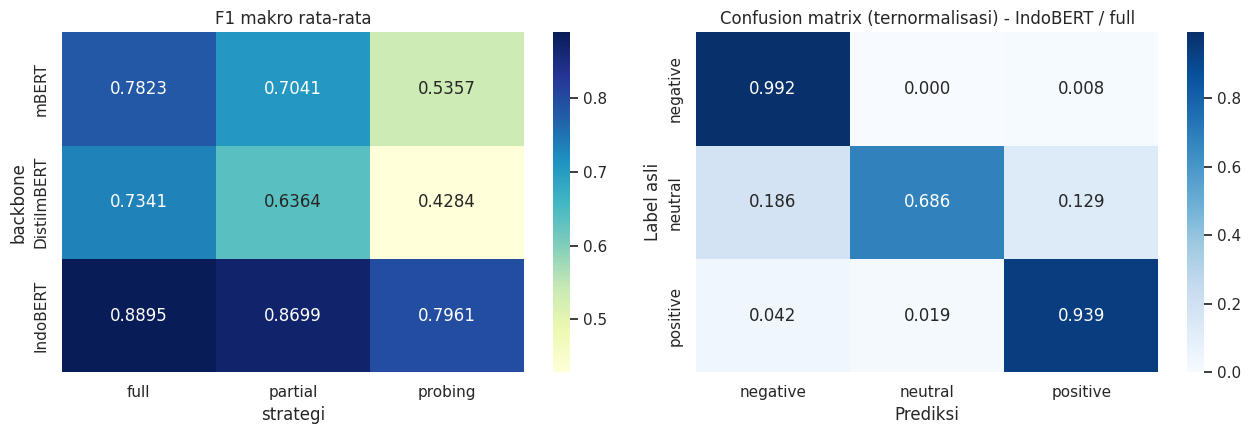

In [ ]:
# Heatmap F1 makro + confusion matrix konfigurasi terbaik (dijumlah atas semua seed)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
piv = agg.pivot(index="backbone", columns="strategi", values="f1_macro_mean").loc[order_b, order_s]
sns.heatmap(piv, annot=True, fmt=".4f", cmap="YlGnBu", ax=axes[0]); axes[0].set_title("F1 makro rata-rata")

best = agg.loc[agg.f1_macro_mean.idxmax()]
sel = hasil[(hasil.backbone == best.backbone) & (hasil.strategi == best.strategi)]
cm = np.sum([np.array(json.loads(c)) for c in sel.cm], axis=0)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".3f", cmap="Blues", xticklabels=LABEL2ID, yticklabels=LABEL2ID, ax=axes[1])
axes[1].set_xlabel("Prediksi"); axes[1].set_ylabel("Label asli")
axes[1].set_title(f"Confusion matrix (ternormalisasi) - {best.backbone} / {best.strategi}")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"fig_heatmap_cm_{KODE}.png"), dpi=150); plt.show()

## 9. Analisis berbasis bukti
Bandingkan selisih F1 makro uji pada seed yang sama dengan simpangan antar-seed. Gunakan tiga seed sebagai bukti deskriptif. Bandingkan waktu latih antar-model hanya pada tipe GPU yang sama.

In [ ]:
A = agg.set_index(["backbone", "strategi"])
scores = hasil.pivot(index="seed", columns=["backbone", "strategi"], values="f1_macro")

def paired_f1(first, second):
    delta = 100 * (scores[first] - scores[second])
    spread = f"; SD selisih={delta.std():.2f} poin" if len(delta) > 1 else ""
    print(f"  {'/'.join(first)} vs {'/'.join(second)}: Δ per seed {delta.round(2).to_dict()}, "
          f"rata-rata={delta.mean():+.2f} poin{spread}")

print("H1 — F1 makro uji pada full fine-tuning")
full = A.xs("full", level="strategi").sort_values("f1_macro_mean", ascending=False)
display(full[["f1_macro_mean", "f1_macro_std", "train_time_s_mean", "params_total"]].join(
    lat_df.set_index("backbone")[["infer_ms_mean"]]
))
paired_f1(("IndoBERT", "full"), ("mBERT", "full"))
paired_f1(("mBERT", "full"), ("DistilmBERT", "full"))

print("\nH2 — Strategi per backbone")
for b in order_b:
    display(A.loc[b, ["f1_macro_mean", "f1_macro_std", "train_time_s_mean",
                     "peak_mem_mb_mean", "params_trainable", "pct_trainable"]])
    paired_f1((b, "full"), (b, "partial"))
    paired_f1((b, "full"), (b, "probing"))

print("\nH3 — Efisiensi DistilmBERT vs mBERT (full fine-tuning)")
d, m = A.loc[("DistilmBERT", "full")], A.loc[("mBERT", "full")]
full_gpu = hasil.loc[(hasil["strategi"] == "full") & hasil["backbone"].isin(["mBERT", "DistilmBERT"]), "gpu"]
if full_gpu.nunique() == 1:
    print(f"  Speedup latih: {m.train_time_s_mean / d.train_time_s_mean:.2f}× pada {full_gpu.iloc[0]}")
else:
    print("  Rasio waktu latih dilewati karena tipe GPU berbeda.")
print(f"  Speedup inferensi: {lat_df.set_index('backbone').loc['DistilmBERT','speedup_vs_mBERT']:.2f}×")
paired_f1(("mBERT", "full"), ("DistilmBERT", "full"))

print("\nKandidat dengan F1 uji dalam 2 poin dari skor tertinggi")
candidates = agg.loc[agg["f1_macro_mean"] >= best.f1_macro_mean - 0.02].copy()
candidates["latensi_satu_sesi_ms"] = candidates["backbone"].map(latency_by_backbone).astype(float)
display(candidates[["backbone", "strategi", "f1_macro_mean", "latensi_satu_sesi_ms",
                    "train_time_s_mean", "peak_mem_mb_mean"]].sort_values("latensi_satu_sesi_ms"))

print(f"\nKonfigurasi terbaik berdasarkan F1 uji: {best.backbone} / {best.strategi}")
print(classification_report(
    np.repeat(LABEL_IDS, cm.sum(axis=1)),
    np.concatenate([np.repeat(LABEL_IDS, row) for row in cm]),
    labels=LABEL_IDS, target_names=list(LABEL2ID), digits=4, zero_division=0,
))

H1 — F1 makro uji pada full fine-tuning


,f1_macro_mean,f1_macro_std,train_time_s_mean,params_total,infer_ms_mean
backbone,,,,,
IndoBERT,0.889511,0.005267,134.687421,123853059,9.091354
mBERT,0.782283,0.006909,157.984184,177265155,8.592303
DistilmBERT,0.734113,0.003531,109.517219,134736387,3.933852


  IndoBERT/full vs mBERT/full: Δ per seed {42: 11.06, 123: 10.41, 2024: 10.7}, rata-rata=+10.72 poin; SD selisih=0.33 poin
  mBERT/full vs DistilmBERT/full: Δ per seed {42: 4.99, 123: 5.49, 2024: 3.97}, rata-rata=+4.82 poin; SD selisih=0.78 poin

H2 — Strategi per backbone


,f1_macro_mean,f1_macro_std,train_time_s_mean,peak_mem_mb_mean,params_trainable,pct_trainable
strategi,,,,,,
full,0.782283,0.006909,157.984184,3882.735514,177265155,100.000000
partial,0.704050,0.007819,99.858813,1957.303874,42529539,23.992047
probing,0.535727,0.003104,72.410831,877.704102,2307,0.001301


  mBERT/full vs mBERT/partial: Δ per seed {42: 8.15, 123: 7.7, 2024: 7.62}, rata-rata=+7.82 poin; SD selisih=0.29 poin
  mBERT/full vs mBERT/probing: Δ per seed {42: 24.79, 123: 25.19, 2024: 23.99}, rata-rata=+24.66 poin; SD selisih=0.61 poin


,f1_macro_mean,f1_macro_std,train_time_s_mean,peak_mem_mb_mean,params_trainable,pct_trainable
strategi,,,,,,
full,0.734113,0.003531,109.517219,2618.449056,134736387,100.000000
partial,0.636356,0.025328,82.200678,1181.964193,21265923,15.783356
probing,0.428427,0.004795,63.231539,703.326497,2307,0.001712


  DistilmBERT/full vs DistilmBERT/partial: Δ per seed {42: 10.63, 123: 11.54, 2024: 7.15}, rata-rata=+9.78 poin; SD selisih=2.32 poin
  DistilmBERT/full vs DistilmBERT/probing: Δ per seed {42: 30.31, 123: 31.07, 2024: 30.33}, rata-rata=+30.57 poin; SD selisih=0.43 poin


,f1_macro_mean,f1_macro_std,train_time_s_mean,peak_mem_mb_mean,params_trainable,pct_trainable
strategi,,,,,,
full,0.889511,0.005267,134.687421,2997.566406,123853059,100.000000
partial,0.869931,0.019564,94.317467,1615.175944,42529539,34.338707
probing,0.796068,0.006954,68.993087,641.038574,2307,0.001863


  IndoBERT/full vs IndoBERT/partial: Δ per seed {42: 0.85, 123: 1.38, 2024: 3.64}, rata-rata=+1.96 poin; SD selisih=1.48 poin
  IndoBERT/full vs IndoBERT/probing: Δ per seed {42: 9.9, 123: 10.16, 2024: 7.97}, rata-rata=+9.34 poin; SD selisih=1.20 poin

H3 — Efisiensi DistilmBERT vs mBERT (full fine-tuning)
  Speedup latih: 1.44× pada Tesla T4
  Speedup inferensi: 2.18×
  mBERT/full vs DistilmBERT/full: Δ per seed {42: 4.99, 123: 5.49, 2024: 3.97}, rata-rata=+4.82 poin; SD selisih=0.78 poin

Kandidat dengan F1 uji dalam 2 poin dari skor tertinggi


,backbone,strategi,f1_macro_mean,latensi_satu_sesi_ms,train_time_s_mean,peak_mem_mb_mean
6,IndoBERT,full,0.889511,9.091354,134.687421,2997.566406
7,IndoBERT,partial,0.869931,9.091354,94.317467,1615.175944



Konfigurasi terbaik berdasarkan F1 uji: IndoBERT / full
              precision    recall  f1-score   support

    negative     0.8900    0.9918    0.9382       612
     neutral     0.9378    0.6856    0.7921       264
    positive     0.9376    0.9391    0.9384       624

    accuracy                         0.9160      1500
   macro avg     0.9218    0.8722    0.8895      1500
weighted avg     0.9182    0.9160    0.9125      1500



### 9.1 Baseline TF–IDF
Latih TF–IDF dan regresi logistik pada subset latih yang sama, lalu hitung skor sekali pada 500 uji resmi.

In [ ]:
if MODE == "penuh":
    if os.path.exists(TFIDF_CSV):
        baseline = pd.read_csv(TFIDF_CSV, dtype={"kode": str})
    else:
        tfidf = make_pipeline(
            TfidfVectorizer(ngram_range=(1, 2), min_df=2),
            LogisticRegression(max_iter=1000, random_state=SUBSET_SEED),
        )
        start = time.perf_counter()
        tfidf.fit(train_df["text"], train_df["y"])
        train_seconds = time.perf_counter() - start
        predictions = tfidf.predict(test_df["text"])
        baseline = pd.DataFrame([{
            "kode": KODE, "model": "TF-IDF + regresi logistik",
            "n_train": len(train_df), "n_test": len(test_df),
            "accuracy": accuracy_score(test_df["y"], predictions),
            "f1_macro": macro_f1(test_df["y"], predictions), "train_time_s_cpu": train_seconds,
        }])
        baseline.to_csv(TFIDF_CSV + ".tmp", index=False)
        os.replace(TFIDF_CSV + ".tmp", TFIDF_CSV)
    display(baseline)
else:
    print("Baseline TF-IDF dijalankan pada mode penuh.")

,kode,model,n_train,n_test,accuracy,f1_macro,train_time_s_cpu
0,22583772,TF-IDF + regresi logistik,6000,500,0.712,0.602236,1.462683


### 9.2 Jawaban tiga pertanyaan riset wajib

**Q1 — Backbone mana yang memberi trade-off akurasi dan efisiensi terbaik?**  
Perbandingan pada strategi yang sama (full fine-tuning, 3 seed):

| Backbone | F1 makro ± SD | Waktu latih (s) | Inferensi (ms/kalimat, satu sesi) | Parameter |
|---|---|---|---|---|
| IndoBERT | 88,95 ± 0,53 | 134,7 ± 7,1 | 9,09 | 123,9 M |
| mBERT | 78,23 ± 0,69 | 158,0 ± 10,0 | 8,59 | 177,3 M |
| DistilmBERT | 73,41 ± 0,35 | 109,5 ± 0,7 | 3,93 | 134,7 M |

IndoBERT memberi trade-off terbaik. F1-nya 10,72 poin di atas mBERT (positif di ketiga seed, SD selisih hanya 0,33), padahal parameternya lebih sedikit, waktu latihnya lebih singkat, dan latensinya setara (9,09 vs 8,59 ms, selisih masih dalam rentang SD antar-pengukuran). Jadi mBERT didominasi IndoBERT pada hampir semua metrik. DistilmBERT memang 2,18× lebih cepat saat inferensi dan 1,44× lebih cepat saat latih dibanding mBERT, tetapi F1-nya turun 4,82 poin dari mBERT dan 15,54 poin dari IndoBERT. Penghematan kecepatan itu tidak sebanding dengan penurunan akurasinya. Penyebab utamanya diduga pretraining: IndoBERT dilatih pada korpus Indonesia, sedangkan dua model lainnya multibahasa.


**Q2 — Seberapa kompetitif strategi hemat komputasi terhadap full fine-tuning?**  
| Backbone | Partial vs full (Δ F1, SD selisih) | Probing vs full (Δ F1, SD selisih) |
|---|---|---|
| IndoBERT | −1,96 poin (1,48) | −9,34 poin (1,20) |
| mBERT | −7,82 poin (0,29) | −24,66 poin (0,61) |
| DistilmBERT | −9,78 poin (2,32) | −30,57 poin (0,43) |

- **IndoBERT + partial freezing** cukup kompetitif. Selisih rata-ratanya 1,96 poin, tetapi per seed berkisar 0,85 / 1,38 / 3,64, dan SD partial (1,96) jauh lebih besar daripada full (0,53). Jadi selisihnya sebanding dengan simpangan antar-seed: belum bisa dikatakan berbeda secara tegas, tetapi hasilnya kurang stabil, dan pada seed 2024 selisihnya melebihi 2 poin. Penghematannya nyata: parameter dilatih 42,5 M (34,3%), waktu latih −30% (94,3 vs 134,7 s), dan memori puncak −46% (1.615 vs 2.998 MiB).
- **Linear probing** tertinggal bermakna di semua backbone (selisih jauh di atas SD). Pada IndoBERT, probing (79,61) masih jauh di atas baseline TF-IDF (60,22) dengan penghematan waktu −49% dan memori −79%, tetapi selisih 9,34 poin terlalu besar bila akurasi menjadi prioritas.
- Pada **mBERT dan DistilmBERT**, strategi hemat tidak kompetitif sama sekali (partial turun 7,8–9,8 poin). Probing keduanya (53,57 dan 42,84) bahkan di bawah baseline TF-IDF, yang menunjukkan representasi [CLS] beku dari model multibahasa kurang cocok untuk SmSA.
- Strategi tidak mengubah arsitektur saat inferensi, jadi latensi pada ketiga strategi tidak menjadi pembeda.


**Q3 — Kombinasi mana yang direkomendasikan dan mengapa?**  
Kriteria yang ditetapkan sebelum memilih: (1) F1 makro tertinggi, (2) kandidat hanya yang F1-nya dalam 2 poin dari skor tertinggi, (3) dari kandidat itu pilih berdasarkan latensi terukur, lalu anggaran latih (waktu dan memori), (4) rekomendasi harus bisa dijelaskan dengan angka.

**Rekomendasi: IndoBERT dengan full fine-tuning** (F1 88,95 ± 0,53; akurasi 91,60 ± 0,20).
- **Akurasi:** tertinggi dan paling stabil antar-seed. Hanya IndoBERT full dan partial yang lolos kriteria 2 poin.
- **Latensi:** kandidat yang lolos berlatensi sama (≈ 9 ms/kalimat pada T4, batch 1), cukup untuk pemakaian real-time. DistilmBERT lebih cepat (3,93 ms) tetapi gagal kriteria akurasi.
- **Anggaran komputasi:** satu run ≈ 135 detik dan ≈ 3 GB memori GPU, masih terjangkau di T4 gratis.
- **Keterjelasan:** keunggulan IndoBERT atas mBERT konsisten di ketiga seed dan dapat dijelaskan dari pretraining berbahasa Indonesia.

**Alternatif bila anggaran latih sangat terbatas: IndoBERT dengan partial freezing**, yang menghemat 30% waktu dan 46% memori dengan F1 87–89 (selisih 1,96 poin), dengan catatan hasilnya kurang stabil (SD 1,96).

**Kinerja per kelas** (IndoBERT full, gabungan 3 seed): F1 negatif 0,938, netral 0,792, positif 0,938. Recall kelas netral hanya 0,686, jadi sekitar sepertiga kalimat netral salah diprediksi. Ini kelemahan utama model dan perlu dicatat bila dipakai untuk memprioritaskan keluhan. Kemungkinan penyebabnya: kelas netral minoritas (≈ 10% data latih, tetapi ≈ 18% data uji).

**Tidak direkomendasikan:** DistilmBERT (akurasi terlalu rendah), mBERT (didominasi IndoBERT), dan linear probing pada backbone mana pun (akurasi di bawah partial/full, dan di bawah TF-IDF untuk model multibahasa).

## 10. Kesimpulan dan rekomendasi
**Kesimpulan**
- **Backbone paling menentukan.** IndoBERT full mencapai F1 makro 88,95 ± 0,53, unggul 10,72 poin dari mBERT dan 15,54 poin dari DistilmBERT, konsisten di 3 seed. Penyebab yang paling masuk akal adalah pretraining berbahasa Indonesia.
- **Strategi hemat hanya cocok untuk backbone yang sesuai bahasa.** Partial freezing hanya turun 1,96 poin pada IndoBERT, tetapi 7,8–9,8 poin pada mBERT dan DistilmBERT. Linear probing tertinggal jauh, dan pada model multibahasa berada di bawah baseline TF-IDF (60,22).
- **DistilmBERT tidak sepadan.** Inferensinya 2,18× lebih cepat dari mBERT, tetapi F1 turun 4,82 poin.
- **Hipotesis:** H1 terbukti. H2 dan H3 sebagian: syarat "partial < 2 poin" hanya terpenuhi pada IndoBERT, dan penurunan F1 DistilmBERT melebihi 2 poin.

**Rekomendasi**
- **Utama: IndoBERT + full fine-tuning.** F1 tertinggi dan paling stabil, latensi ≈ 9 ms/kalimat (T4, batch 1), biaya latih ≈ 135 detik dan ≈ 3 GB per run.
- **Bila anggaran latih terbatas: IndoBERT + partial freezing.** Waktu latih −30% dan memori −46%, dengan F1 lebih rendah 1,96 poin dan kurang stabil (SD 1,96).
- **Catatan:** recall kelas netral hanya 0,686, jadi kalimat netral perlu dipantau.

**Keterbatasan:** 6.000 sampel latih, tiga epoch, tiga seed, dan konfigurasi tanpa pencarian hiperparameter. Latensi berlaku pada GPU dan konfigurasi benchmark yang dilaporkan.

In [ ]:
# Ringkasan berkas yang harus dikumpulkan
files_to_check = [HASIL_CSV, REKAP_CSV]
if MODE == "penuh":
    files_to_check.append(TFIDF_CSV)
for f in files_to_check:
    print(("OK  " if os.path.exists(f) else "HILANG ") + f)
# Untuk mengunduh dari Colab:
# from google.colab import files; files.download(HASIL_CSV); files.download(REKAP_CSV)

OK  /content/drive/MyDrive/Studio3_SmSA/hasil_smsa_22583772.csv
OK  /content/drive/MyDrive/Studio3_SmSA/rekap_agregat_smsa_22583772.csv
OK  /content/drive/MyDrive/Studio3_SmSA/baseline_tfidf_smsa_22583772.csv
